## Attempt 1-5: Bad results
## Problem lies in the data -> Fix distribution

In [1]:
!pip install -q transformers==4.57.1
!pip install -q datasets soundfile librosa
!pip install -q accelerate
!pip install git+https://github.com/openai/whisper.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 47.7 MB/s eta 0:00:00
  Cloning https://github.com/openai/whisper.git to /tmp/pip-req-build-0gino_md
  Running command git clone --filter=blob:none --quiet https://github.com/openai/whisper.git /tmp/pip-req-build-0gino_md
  Resolved https://github.com/openai/whisper.git to commit c0d2f624c09dc18e709e37c2ad90c039a4eb72a2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for openai-whisper: filename=openai_whisper-20250625-py3-none-any.whl size=803979 sha256=00f4bfcc430f9146298bb43a6d74a8ae645abbb4b138f068804127efee4cae47
  Stored in directory: /tmp/pip-ephem-wheel-cache-9ijswkcs/wheels/c3/03/25/5e0ba78bc27a3a089f137c9f1d92fdfce16d06996c071a016c
Successfully built openai-whisper


In [7]:
import whisper
import torchaudio
import zipfile
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import librosa
import json
import matplotlib.pyplot as plt
from transformers import WhisperFeatureExtractor, WhisperModel
from sklearn.model_selection import train_test_split
import pandas as pd

In [4]:
zip_path = "/content/drive/MyDrive/szakdolgozat/augmented_wavs.zip.zip"
extract_path = "/content/SingMOS"
score_path = "/content/drive/MyDrive/szakdolgozat/augmented_metadata.csv"


with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Done!")

Done!


In [5]:
# params
PRETRAINED = "openai/whisper-small"
SR = 16000
BATCH_SIZE = 8
LR = 1e-4
EPOCHS = 30
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [10]:
scores = pd.read_csv(score_path)
scores.head()

,Unnamed: 0,wav,mos
0,0,sys0005-utt0405.wav,1.0
1,1,sys0005-utt0412.wav,1.0
2,2,sys0005-utt0416.wav,1.0
3,3,sys0005-utt0417.wav,1.0
4,4,sys0005-utt0448.wav,1.0


In [11]:
print(scores.columns)
print(scores.shape)

Index(['Unnamed: 0', 'wav', 'mos'], dtype='object')
(7100, 3)


In [12]:
# local storage for faster read
wav_path = "/content/SingMOS"
scores["wav"] = wav_path + "/" + scores["wav"]
scores.head()

,Unnamed: 0,wav,mos
0,0,/content/SingMOS/sys0005-utt0405.wav,1.0
1,1,/content/SingMOS/sys0005-utt0412.wav,1.0
2,2,/content/SingMOS/sys0005-utt0416.wav,1.0
3,3,/content/SingMOS/sys0005-utt0417.wav,1.0
4,4,/content/SingMOS/sys0005-utt0448.wav,1.0


In [13]:
model = whisper.load_model("base")
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

def whisper_embedding(path):
    audio = whisper.load_audio(path)
    audio = whisper.pad_or_trim(audio)
    mel = whisper.log_mel_spectrogram(audio).to(device)

    with torch.no_grad():
        emb = model.encoder(mel.unsqueeze(0)).cpu().numpy()

    # (1, T, 512)
    return emb.mean(axis=1).flatten()

100%|████████████████████████████████████████| 139M/139M [00:00<00:00, 312MiB/s]


In [ ]:
X = []
y = []

for _, row in scores.iterrows():
    emb = whisper_embedding(row["wav"])
    X.append(emb)
    y.append(row["mos"])

X = np.vstack(X)
y = np.array(y)

In [ ]:
# Save embeddings - augmented
np.savez("whisper_mos_embeddings_V2.npz", X=X, y=y)
np.savez("/content/drive/MyDrive/SingMOS/whisper_mos_embeddings_V2.npz", X=X, y=y)

In [14]:
data = np.load("/content/drive/MyDrive/SingMOS/whisper_mos_embeddings_V2.npz")
X = data['X']
y = data['y']
print(X.shape, y.shape)

(7100, 512) (7100,)


In [18]:
class EmbeddingDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return {"embedding": self.X[idx], "mos": self.y[idx]}

dataset = EmbeddingDataset(X, y)

train_idx, temp_idx = train_test_split(
    range(len(dataset)),
    test_size=0.3,
    random_state=42,
    shuffle=True
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    random_state=42,
    shuffle=True
)

train_ds = torch.utils.data.Subset(dataset, train_idx)
val_ds   = torch.utils.data.Subset(dataset, val_idx)
test_ds  = torch.utils.data.Subset(dataset, test_idx)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=8, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=8, shuffle=False)

In [19]:
class MOSRegressor(nn.Module):
    def __init__(self, input_dim, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden, hidden//2),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden//2, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

Epoch 01 | train_loss=0.0933 val_loss=0.0651
Epoch 02 | train_loss=0.0693 val_loss=0.0646
Epoch 03 | train_loss=0.0673 val_loss=0.0626
Epoch 04 | train_loss=0.0656 val_loss=0.0613
Epoch 05 | train_loss=0.0649 val_loss=0.0594
Epoch 06 | train_loss=0.0635 val_loss=0.0591
Epoch 07 | train_loss=0.0627 val_loss=0.0579
Epoch 08 | train_loss=0.0621 val_loss=0.0578
Epoch 09 | train_loss=0.0614 val_loss=0.0573
Epoch 10 | train_loss=0.0619 val_loss=0.0576
Epoch 11 | train_loss=0.0601 val_loss=0.0563
Epoch 12 | train_loss=0.0608 val_loss=0.0557
Epoch 13 | train_loss=0.0600 val_loss=0.0569
Epoch 14 | train_loss=0.0591 val_loss=0.0552
Epoch 15 | train_loss=0.0587 val_loss=0.0585
Epoch 16 | train_loss=0.0588 val_loss=0.0560
Epoch 17 | train_loss=0.0587 val_loss=0.0547
Epoch 18 | train_loss=0.0584 val_loss=0.0552
Epoch 19 | train_loss=0.0586 val_loss=0.0552
Epoch 20 | train_loss=0.0585 val_loss=0.0548
Epoch 21 | train_loss=0.0578 val_loss=0.0540
Epoch 22 | train_loss=0.0571 val_loss=0.0572
Epoch 23 |

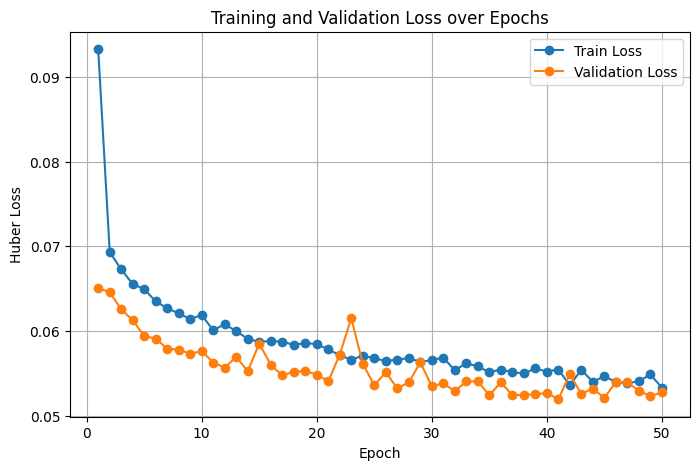

In [20]:
train_losses = []
val_losses = []

device = "cuda" if torch.cuda.is_available() else "cpu"
model = MOSRegressor(input_dim=X.shape[1]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 50

for epoch in range(EPOCHS):

    model.train()
    train_loss = 0.0
    for batch in train_loader:
        emb = batch["embedding"].to(device)
        mos = batch["mos"].to(device)

        pred = model(emb)
        loss = F.huber_loss(pred, mos, delta=0.1)

        optimizer.zero_grad()
        loss.backward()

        optimizer.step()
        train_loss += loss.item() * emb.size(0)

    train_loss /= len(train_ds)
    train_losses.append(train_loss)



    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
            emb = batch["embedding"].to(device)
            mos = batch["mos"].to(device)
            pred = model(emb)
            val_loss += F.huber_loss(pred, mos, delta=0.1).item() * emb.size(0)
    val_loss /= len(val_ds)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1:02d} | train_loss={train_loss:.4f} val_loss={val_loss:.4f}")


plt.figure(figsize=(8,5))
plt.plot(range(1, EPOCHS+1), train_losses, label="Train Loss", marker='o')
plt.plot(range(1, EPOCHS+1), val_losses, label="Validation Loss", marker='o')
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.title("Training and Validation Loss over Epochs")
plt.legend()
plt.grid(True)
plt.show()

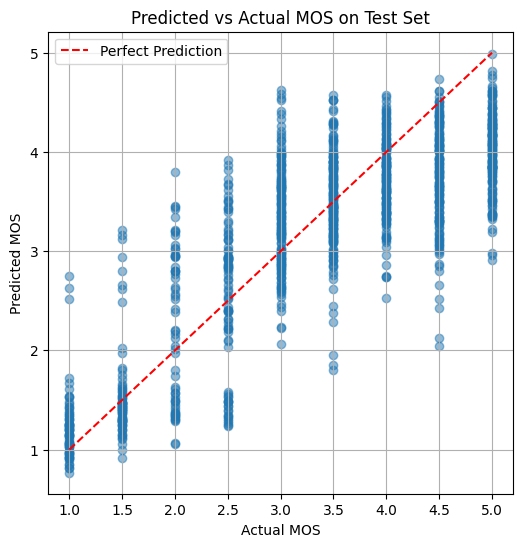

In [22]:

model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for batch in test_loader:
        emb = batch["embedding"].to(device)
        mos = batch["mos"].to(device)
        pred = model(emb)

        all_preds.append(pred.cpu())
        all_targets.append(mos.cpu())


all_preds = torch.cat(all_preds).numpy()
all_targets = torch.cat(all_targets).numpy()


plt.figure(figsize=(6,6))
plt.scatter(all_targets, all_preds, alpha=0.5)
plt.plot([all_targets.min(), all_targets.max()],
         [all_targets.min(), all_targets.max()],
         'r--', label='Perfect Prediction')
plt.xlabel("Actual MOS")
plt.ylabel("Predicted MOS")
plt.title("Predicted vs Actual MOS on Test Set")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(all_targets, all_preds)
mae = mean_absolute_error(all_targets, all_preds)
rmse = np.sqrt(mean_squared_error(all_targets, all_preds))

print(f"R2 Score: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

R2 Score: 0.6330
MAE: 0.5735
RMSE: 0.7271
